In [7]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in el_split_analysis.py next to this notebook
# (run it as a script to regenerate everything: python el_split_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import el_split_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,fictrac_scan_num,closed_loop,dark,rnai_line,gal4_line,usable,fictrac_dat_file,notes,session,fly_id,rnai
0,08_04_2024,fly1,closed_loop-000,0.0,1,0,control,ELDR009,1,fictrac-20240408_104747.dat,NaN,closed_loop-000,08_04_2024_fly1_ELDR009_control,control
1,08_04_2024,fly1,dark-001,1.0,0,1,control,ELDR009,1,fictrac-20240408_104747.dat,NaN,dark-001,08_04_2024_fly1_ELDR009_control,control
2,08_04_2024,fly1,closed_loop-002,2.0,2,0,control,ELDR009,1,fictrac-20240408_104747.dat,NaN,closed_loop-002,08_04_2024_fly1_ELDR009_control,control
3,08_04_2024,fly1,dark-003,3.0,0,2,control,ELDR009,1,fictrac-20240408_104747.dat,NaN,dark-003,08_04_2024_fly1_ELDR009_control,control
5,08_04_2024,fly2,closed_loop-002,2.0,1,0,control,ELDR009,1,fictrac-20240408_120523.dat,NaN,closed_loop-002,08_04_2024_fly2_ELDR009_control,control


## Offset vector length and variance, dark vs closed loop

offset_var_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,rnai,12.410198,2,29,6.205099,15.612408,2.500498e-05,0.518471,NaN
1,dark,11.730752,1,29,11.730752,68.914501,3.758681e-09,0.703823,1.0
2,Interaction,6.090762,2,29,3.045381,17.890662,8.684575e-06,0.552340,NaN


offset_var_pairwise_dark_effect


,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,rnai_67968,False,True,-4.796534,18.303620,two-sided,0.000138,0.000277,holm,164.396,-2.021550
1,rnai,-,control,vglut_rnai,False,True,1.009357,18.156129,two-sided,0.326067,0.326067,holm,0.56,0.416823
2,rnai,-,rnai_67968,vglut_rnai,False,True,5.086745,20.000000,two-sided,0.000056,0.000169,holm,325.912,2.086628
3,dark,-,0,1,True,True,-5.742635,31.000000,two-sided,0.000003,NaN,NaN,7347.16,-1.126381
4,rnai * dark,control,0,1,True,True,-5.851264,9.000000,two-sided,0.000243,0.000487,holm,134.015,-2.188727
5,rnai * dark,rnai_67968,0,1,True,True,-0.092206,10.000000,two-sided,0.928355,0.928355,holm,0.299,-0.034135
6,rnai * dark,vglut_rnai,0,1,True,True,-8.996804,10.000000,two-sided,0.000004,0.000012,holm,4587.466,-2.245787


offset_var_pairwise_group_effect


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-5.742635,31.000000,two-sided,2.556636e-06,NaN,NaN,7347.16,-1.126381
1,rnai,-,control,rnai_67968,False,True,-4.796534,18.303620,two-sided,1.382781e-04,2.765562e-04,holm,164.396,-2.021550
2,rnai,-,control,vglut_rnai,False,True,1.009357,18.156129,two-sided,3.260667e-01,3.260667e-01,holm,0.56,0.416823
3,rnai,-,rnai_67968,vglut_rnai,False,True,5.086745,20.000000,two-sided,5.632353e-05,1.689706e-04,holm,325.912,2.086628
4,dark * rnai,0,control,rnai_67968,False,True,-6.661009,17.307142,two-sided,3.662934e-06,1.831467e-05,holm,5256.791,-2.824240
5,dark * rnai,0,control,vglut_rnai,False,True,1.662620,17.341658,two-sided,1.143558e-01,4.574232e-01,holm,1.008,0.704817
6,dark * rnai,0,rnai_67968,vglut_rnai,False,True,9.658461,20.000000,two-sided,5.656899e-09,3.394139e-08,holm,1.21e+06,3.961987
7,dark * rnai,1,control,rnai_67968,False,True,-1.033116,18.943102,two-sided,3.145599e-01,8.376985e-01,holm,0.57,-0.432357
8,dark * rnai,1,control,vglut_rnai,False,True,0.281956,17.414432,two-sided,7.813009e-01,8.376985e-01,holm,0.402,0.115951
9,dark * rnai,1,rnai_67968,vglut_rnai,False,True,1.112224,20.000000,two-sided,2.792328e-01,8.376985e-01,holm,0.597,0.456244


offset_n_flies


,rnai,n_flies
0,control,10
1,rnai_67968,11
2,vglut_rnai,11


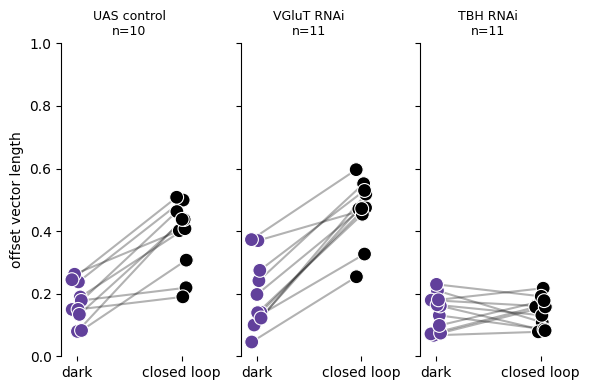

In [9]:
offset_unique, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PV magnitude vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/group_comparison.py:172: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


rho_mean_over_speed_tests


,condition,test,comparison,statistic,p,p_holm
0,closed loop,Kruskal-Wallis,all groups,9.052583,0.010821,NaN
1,closed loop,Mann-Whitney U,UAS control vs VGluT RNAi,58.000000,0.860259,0.860259
2,closed loop,Mann-Whitney U,UAS control vs TBH RNAi,94.000000,0.006706,0.020119
3,closed loop,Mann-Whitney U,VGluT RNAi vs TBH RNAi,97.000000,0.018082,0.036163
4,dark,Kruskal-Wallis,all groups,9.059504,0.010783,NaN
5,dark,Mann-Whitney U,UAS control vs VGluT RNAi,73.000000,0.217832,0.217832
6,dark,Mann-Whitney U,UAS control vs TBH RNAi,96.000000,0.004346,0.013037
7,dark,Mann-Whitney U,VGluT RNAi vs TBH RNAi,89.000000,0.065971,0.131942


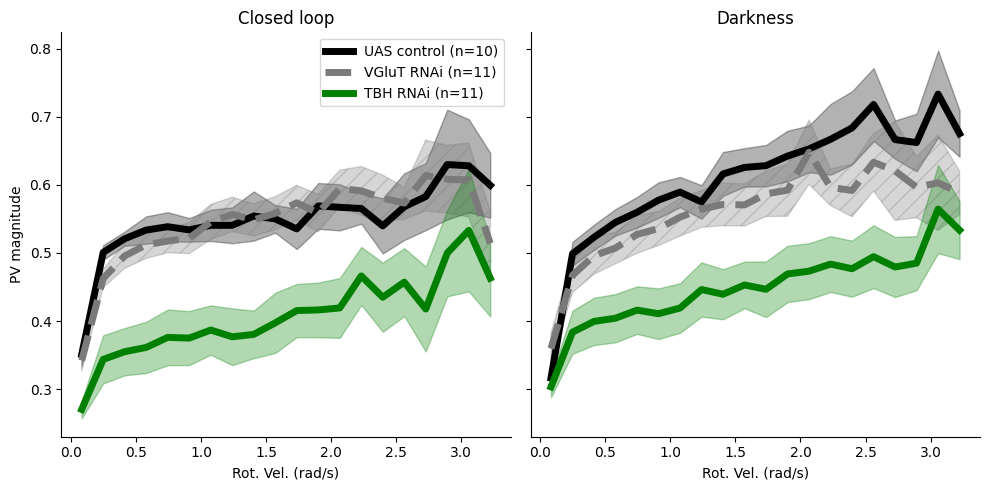

In [10]:
rho_grouped, rho_tables = ana.rho_analysis(sess_manager)
for name, table in rho_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PVA velocity vs rotation speed

dphi_ols_closed_loop
                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.253
Model:                            OLS   Adj. R-squared:                  0.247
Method:                 Least Squares   F-statistic:                     42.88
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           4.33e-38
Time:                        15:44:03   Log-Likelihood:                -307.27
No. Observations:                 640   AIC:                             626.5
Df Residuals:                     634   BIC:                             653.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

,condition,terms,F,p
0,closed_loop,slope differences (dh:group),2.789961,0.062178
1,closed_loop,intercept differences (group),0.046985,0.954105
2,dark,slope differences (dh:group),1.678449,0.187420
3,dark,intercept differences (group),2.275171,0.103545


dphi_coefficients


,condition,term,coef,p,p_holm
0,closed_loop,"dh:C(rnai, Treatment(""rnai_67968""))[T.control]",0.023103,0.465314,0.465314
1,closed_loop,"dh:C(rnai, Treatment(""rnai_67968""))[T.vglut_rnai]",0.071515,0.020806,0.041613
2,dark,"dh:C(rnai, Treatment(""rnai_67968""))[T.control]",0.046282,0.076721,0.153441
3,dark,"dh:C(rnai, Treatment(""rnai_67968""))[T.vglut_rnai]",0.033926,0.204207,0.204207


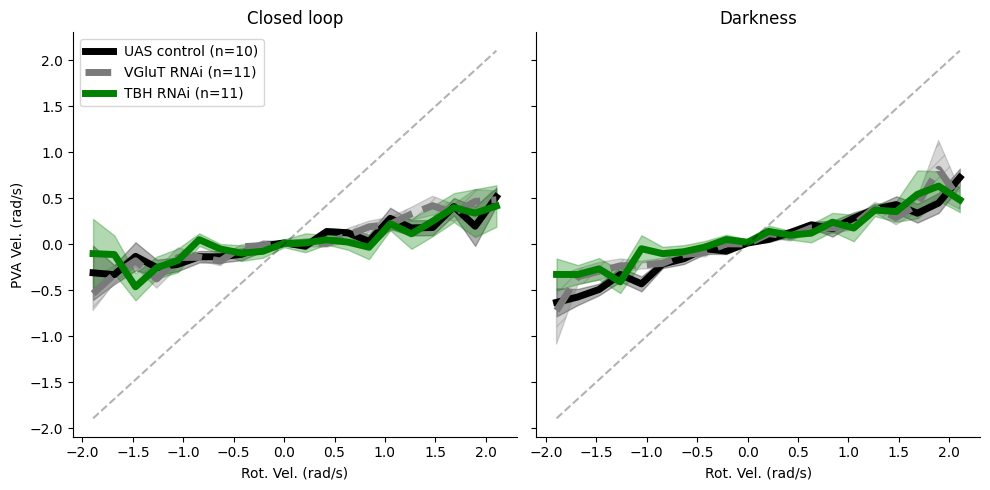

In [11]:
dphi_grouped, dphi_tables = ana.dphi_analysis(sess_manager)
for name, table in dphi_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Bump width

bump_width_tests


,family,comparison,n,W,p,p_holm
0,closed loop vs dark,UAS control,10.0,20.0,0.492188,0.492188
1,closed loop vs dark,VGluT RNAi,11.0,17.0,0.174805,0.349609
2,closed loop vs dark,TBH RNAi,11.0,1.0,0.001953,0.005859
3,"closed loop, between groups",UAS control vs VGluT RNAi,NaN,23.0,0.026544,0.026544
4,"closed loop, between groups",UAS control vs TBH RNAi,NaN,1.0,0.000165,0.000495
5,"closed loop, between groups",VGluT RNAi vs TBH RNAi,NaN,19.0,0.007097,0.014194


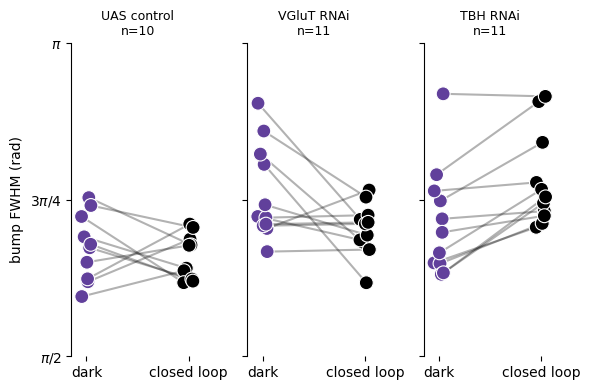

In [12]:
widths, width_tables = ana.width_analysis(sess_manager)

for name, table in width_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Closed-loop and dark heatmaps of every fly

In [13]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

32